1. IMPORT LIBRARIES

In [1]:
import os
import cv2
import numpy as np
import pandas as pd
import tensorflow as tf

from tensorflow.keras.applications.resnet50 import preprocess_input
from tensorflow.keras.applications import ResNet50
from sklearn.model_selection import train_test_split

c:\Users\BLESSED-PC\AppData\Local\Programs\Python\Python313\Lib\site-packages\requests\__init__.py:113: RequestsDependencyWarning: urllib3 (2.2.3) or chardet (7.3.0)/charset_normalizer (3.4.0) doesn't match a supported version!
  warnings.warn(


In [70]:
import json

In [23]:
from sklearn.neighbors import NearestNeighbors

In [27]:
import matplotlib.pyplot as plt

In [66]:
import joblib

2. IMAGE PATHS AND LABELS

In [2]:
image_paths = []

for file in os.listdir("../data/images"):
    image_paths.append(
        os.path.join("../data/images", file)
    )

In [71]:
with open("image_paths.json", "w") as f:
    json.dump(image_paths, f)

3. IMAGE LOADING FUNCTION

In [3]:
def load_image(path):

    image = tf.io.read_file(path)
    image = tf.image.decode_jpeg(image, channels=3)

    image = tf.image.resize(image, (224, 224))

    image = preprocess_input(image)

    return image

4. DATASET

In [6]:
batch_size = 32

data = tf.data.Dataset.from_tensor_slices(image_paths)

data = data.map(
    load_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

data = data.batch(batch_size)

7. BUILD MODEL

In [9]:
base_model = ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model.trainable = False

model = tf.keras.Sequential([
    base_model,
    tf.keras.layers.GlobalAveragePooling2D()
])

In [63]:
model.save("fashionModel.keras")

In [61]:
#save model for later use
tf.saved_model.save(model, "fashion_model")

INFO:tensorflow:Assets written to: fashion_model\assets


INFO:tensorflow:Assets written to: fashion_model\assets


In [ ]:
features = model.predict(data, verbose=0)

In [19]:
embeddings = []
embeddings.append(features)
embeddings = np.array(embeddings)

In [60]:
#Save embeddings for later use
np.save("embeddings.npy", embeddings)

In [21]:
embeddings[0].shape

(44441, 2048)

Nearest neighbours

In [50]:
knn = NearestNeighbors(
    n_neighbors=5,
    metric="euclidean"
)

knn.fit(embeddings[0])

distances, indices = knn.kneighbors(embeddings[0])

In [67]:
#save knn model for later use
joblib.dump(knn, "knn_model.pkl")

['knn_model.pkl']

In [51]:
for distance, index in zip(distances[0], indices[0]):

    print(
        "Image:",
        os.path.basename(image_paths[index]),
        "Distance:",
        distance
    )

Image: 10000.jpg Distance: 6.743495646333031e-07
Image: 39330.jpg Distance: 24.25296401977539
Image: 5575.jpg Distance: 24.281702041625977
Image: 11260.jpg Distance: 24.602426528930664
Image: 6574.jpg Distance: 25.74301528930664


In [68]:
def model_predict(image_path):

    image = load_image(image_path)
    image = tf.expand_dims(image, axis=0)

    features = model.predict(image, verbose=0)

    distances, indices = knn.kneighbors(features)

    return distances, indices

In [52]:
res = model.predict(load_image('test.jpg').numpy().reshape(1, 224, 224, 3))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 288ms/step


In [53]:
test_distance, test_indices = knn.kneighbors(res)

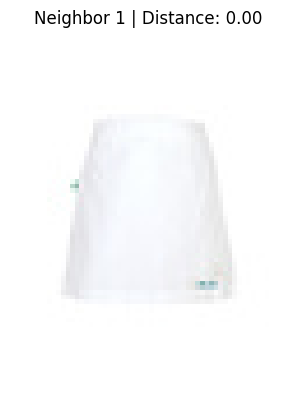

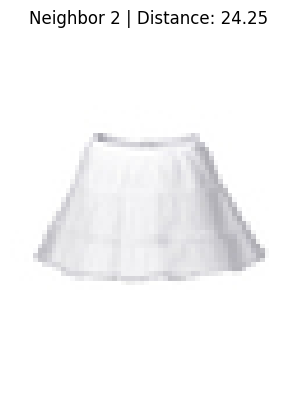

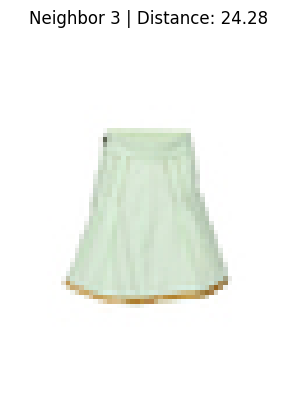

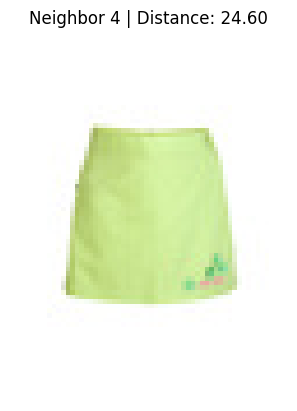

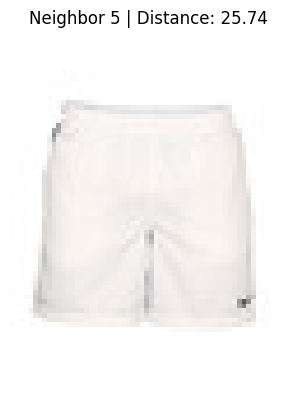

In [54]:
for i, idx in enumerate(indices[0]):

    img = cv2.imread(image_paths[idx])
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    plt.figure()
    plt.imshow(img)
    plt.title(f"Neighbor {i+1} | Distance: {distances[0][i]:.2f}")
    plt.axis("off")
    plt.show()

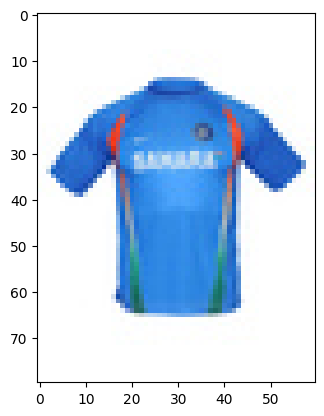

In [48]:
img = cv2.imread('test.jpg')
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
plt.figure()
plt.imshow(img)

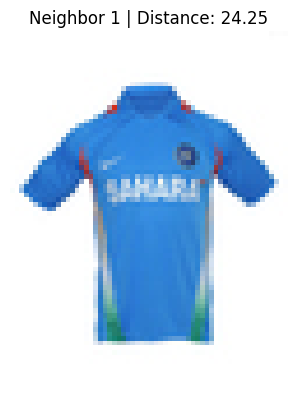

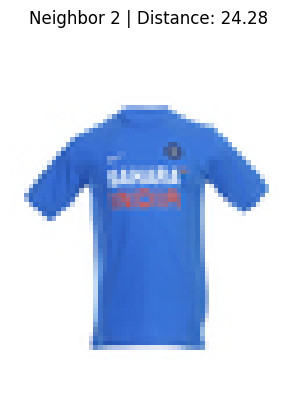

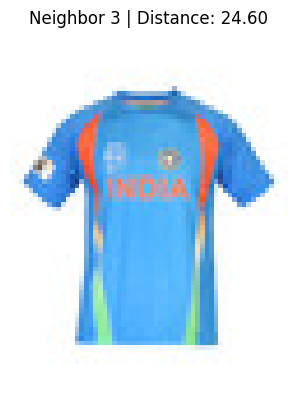

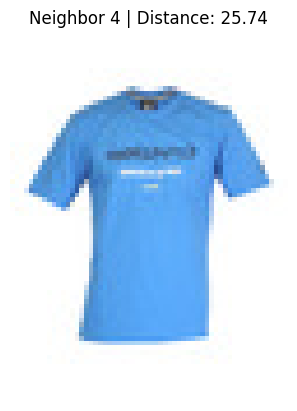

In [57]:
for i, idx in enumerate(test_indices[0]):

    if i == 0:
        continue
    else:
        img = cv2.imread(image_paths[idx])
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        plt.figure()
        plt.imshow(img)
        plt.title(f"Neighbor {i} | Distance: {distances[0][i]:.2f}")
        plt.axis("off")
        plt.show()